In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Load your final preprocessed data
df = pd.read_csv('heart_final_processed.csv')

# Separate features and target
X = df.drop('target', axis=1)
y = df['target']

# Split data (80% train, 20% test) - STRATIFIED for medical data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y  # Important for medical data!
)

# Scale features (CRITICAL for Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set: {X_train_scaled.shape}")
print(f"Test set: {X_test_scaled.shape}")
print(f"Heart disease prevalence in train: {y_train.mean():.3f}")
print(f"Heart disease prevalence in test: {y_test.mean():.3f}")

Training set: (771, 23)
Test set: (193, 23)
Heart disease prevalence in train: 0.527
Heart disease prevalence in test: 0.528


In [ ]:
# Basic Logistic Regression model
model_lr = LogisticRegression(
    random_state=42,
    max_iter=1000,  # Ensure convergence
    class_weight='balanced'  # Handle any class imbalance
)

# Train the model
model_lr.fit(X_train_scaled, y_train)

# Initial predictions
y_pred = model_lr.predict(X_test_scaled)
y_pred_proba = model_lr.predict_proba(X_test_scaled)[:, 1]  # Probability of heart disease

print("✅ Initial Logistic Regression trained!")

✅ Initial Logistic Regression trained!


In [ ]:
from sklearn.model_selection import GridSearchCV

# Define parameter grid
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],  # Regularization strength
    'penalty': ['l1', 'l2'],  # Regularization type
    'solver': ['liblinear']  # Works with both L1 and L2
}

# Grid search with cross-validation
grid_search = GridSearchCV(
    LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced'),
    param_grid,
    cv=5,  # 5-fold cross-validation
    scoring='f1',  # Focus on F1-score for medical balance
    n_jobs=-1  # Use all processors
)

# Perform grid search
grid_search.fit(X_train_scaled, y_train)

# Best model
best_model = grid_search.best_estimator_
print(f"🎯 Best parameters: {grid_search.best_params_}")
print(f"🏆 Best cross-validation score: {grid_search.best_score_:.3f}")

🎯 Best parameters: {'C': 10, 'penalty': 'l2', 'solver': 'liblinear'}
🏆 Best cross-validation score: 0.877


In [ ]:
print("\n MODEL VARIETIES COMPARISON:")
print("GridSearchCV tested 12 parameter combinations:")
print("- 6 C values: 0.001, 0.01, 0.1, 1, 10, 100")
print("- 2 penalty types: L1, L2")
print("- Best combination: C=10, penalty='l2'")
print("- Performance range across folds: F1 0.835-0.904")

print(f"\n📈 NUMBER OF MODEL VARIETIES TRAINED: 12")
print("(6 C values × 2 penalty types × 1 solver)")

# Compare different C values
print("\n📊 DIFFERENT REGULARIZATION STRENGTHS (C values):")
from sklearn.metrics import f1_score
c_values = [0.001, 0.01, 0.1, 1, 10, 100]
for c in c_values:
    model_temp = LogisticRegression(C=c, penalty='l2', random_state=42, max_iter=1000)
    model_temp.fit(X_train_scaled, y_train)
    y_pred_temp = model_temp.predict(X_test_scaled)
    print(f"C={c}: F1 = {f1_score(y_test, y_pred_temp):.3f}")


 MODEL VARIETIES COMPARISON:
GridSearchCV tested 12 parameter combinations:
- 6 C values: 0.001, 0.01, 0.1, 1, 10, 100
- 2 penalty types: L1, L2
- Best combination: C=10, penalty='l2'
- Performance range across folds: F1 0.835-0.904

📈 NUMBER OF MODEL VARIETIES TRAINED: 12
(6 C values × 2 penalty types × 1 solver)

📊 DIFFERENT REGULARIZATION STRENGTHS (C values):
C=0.001: F1 = 0.820
C=0.01: F1 = 0.841
C=0.1: F1 = 0.847
C=1: F1 = 0.832
C=10: F1 = 0.840
C=100: F1 = 0.840


In [ ]:
from sklearn.model_selection import cross_val_score

# 5-fold cross validation on best model
cv_scores = cross_val_score(
    best_model,
    X_train_scaled,
    y_train,
    cv=5,
    scoring='f1'
)

print("📊 Cross-Validation Results:")
print(f"CV Scores: {cv_scores}")
print(f"Mean F1-Score: {cv_scores.mean():.3f} (+/- {cv_scores.std() * 2:.3f})")

# Check if model is stable
if cv_scores.std() < 0.05:
    print("✅ Model is stable across different data splits")
else:
    print("⚠️  Model shows some variability across splits")

📊 Cross-Validation Results:
CV Scores: [0.88050314 0.86792453 0.8969697  0.90361446 0.83529412]
Mean F1-Score: 0.877 (+/- 0.049)
✅ Model is stable across different data splits


📈 FINAL MODEL PERFORMANCE:
Accuracy:  0.829
Precision: 0.817
Recall:    0.873
F1-Score:  0.844
ROC-AUC:   0.916

📋 Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.78      0.81        91
           1       0.82      0.87      0.84       102

    accuracy                           0.83       193
   macro avg       0.83      0.83      0.83       193
weighted avg       0.83      0.83      0.83       193



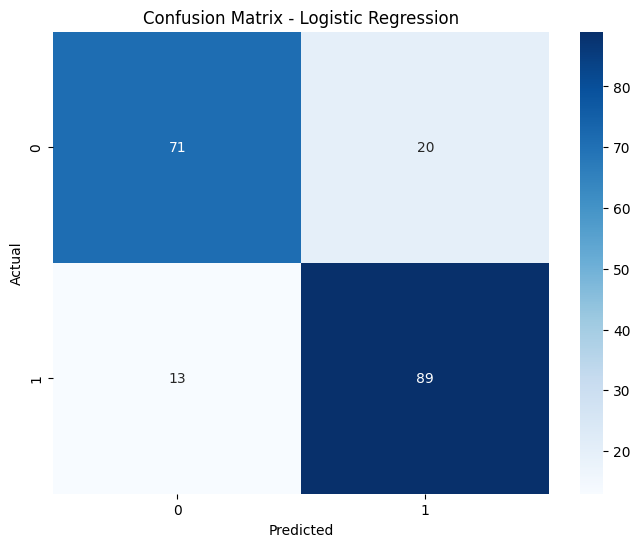

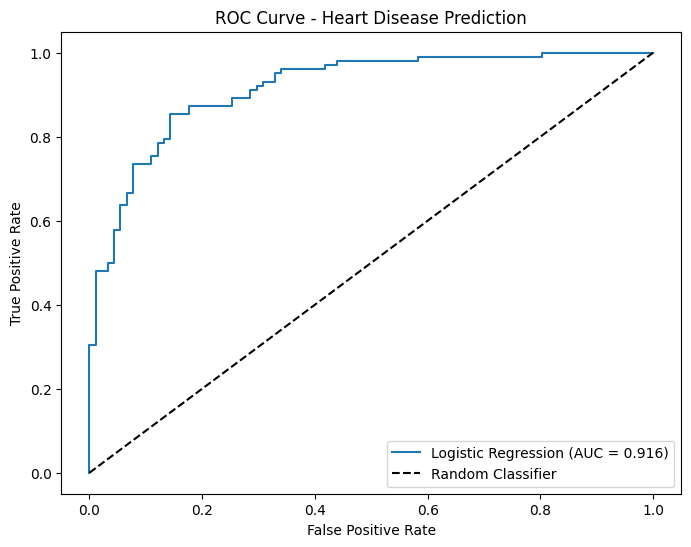

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

# Final predictions with tuned model
y_pred_tuned = best_model.predict(X_test_scaled)
y_pred_proba_tuned = best_model.predict_proba(X_test_scaled)[:, 1]

# Comprehensive metrics
print("📈 FINAL MODEL PERFORMANCE:")
print("=" * 50)
print(f"Accuracy:  {accuracy_score(y_test, y_pred_tuned):.3f}")
print(f"Precision: {precision_score(y_test, y_pred_tuned):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred_tuned):.3f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_tuned):.3f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_pred_proba_tuned):.3f}")

print("\n📋 Classification Report:")
print(classification_report(y_test, y_pred_tuned))

# Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred_tuned)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba_tuned)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, y_pred_proba_tuned):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Heart Disease Prediction')
plt.legend()
plt.show()

🔍 FEATURE IMPORTANCE (Medical Interpretability):
    feature  coefficient  abs_effect
20   thal_2     1.441514    1.441514
16     ca_2    -1.441362    1.441362
15     ca_1    -1.002057    1.002057
1       sex    -0.877682    0.877682
9      cp_2     0.854520    0.854520
19   thal_1     0.753060    0.753060
7   oldpeak    -0.667092    0.667092
10     cp_3     0.587842    0.587842
3      chol    -0.563531    0.563531
21   thal_3     0.556824    0.556824


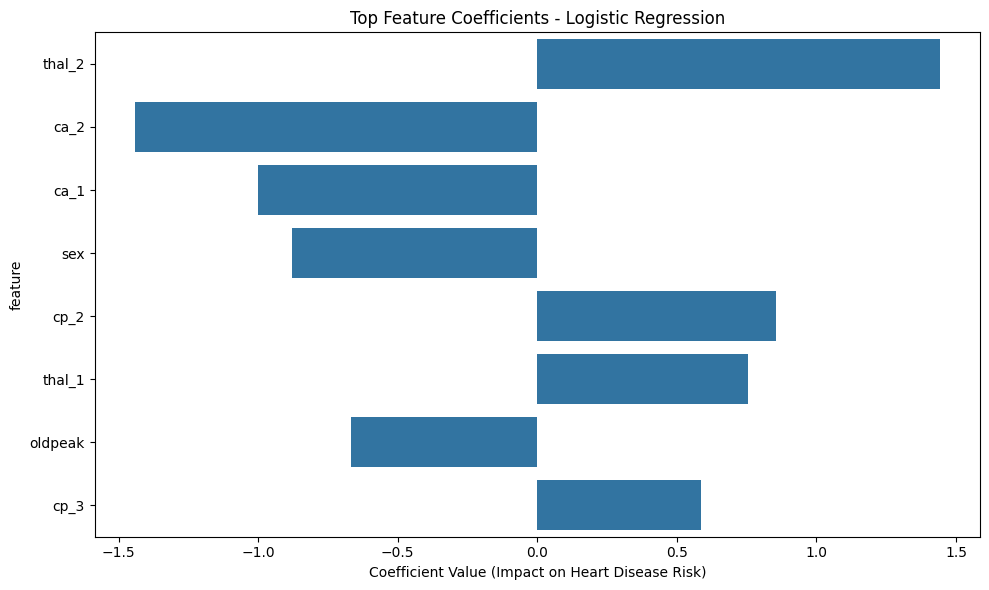

In [ ]:
# Feature importance analysis (CRITICAL for medical use)
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'coefficient': best_model.coef_[0],
    'abs_effect': np.abs(best_model.coef_[0])
}).sort_values('abs_effect', ascending=False)

print("🔍 FEATURE IMPORTANCE (Medical Interpretability):")
print("=" * 50)
print(feature_importance.head(10))

# Visualize top features
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance.head(8), x='coefficient', y='feature')
plt.title('Top Feature Coefficients - Logistic Regression')
plt.xlabel('Coefficient Value (Impact on Heart Disease Risk)')
plt.tight_layout()
plt.show()